# Trabajo Práctico Especial: Análisis de Datos Inside Airbnb (Buenos Aires 2026)

## 1. Análisis Exploratorio Inicial de la Base

### 1.1. Origen, Alcance y Naturaleza de los Datos
* **Fuente de datos (Secundaria):** Los datos provienen de *Inside Airbnb*, un proyecto independiente que extrae información pública de la plataforma Airbnb mediante técnicas de *web scraping*. Al ser recolectados por terceros sin control directo sobre el proceso de muestreo original, constituyen una fuente secundaria que requiere un análisis de calidad.
* **Temporalidad y Alcance:** El dataset representa un corte transversal (*snapshot*) de la oferta de alquileres temporarios publicados en la Ciudad Autónoma de Buenos Aires (CABA) en 2026. 
* **Confiabilidad y Calidad de los Datos:** Al tratarse de una plataforma donde los anfitriones ingresan los datos de sus anuncios a mano, la base es altamente susceptible a errores humanos. 
### 1.2. Criterios de Exclusión y Reducción Dimensional 
El dataset original constaba de 90 columnas. Para focalizar el análisis exploratorio y evitar ruido estadístico, se descartaron 62 variables agrupadas bajo los siguientes criterios metodológicos:

* **Variables Totalmente Nulas:** Atributos con 0 valores no nulos en el corte temporal de CABA (ej. `host_response_rate`, `neighbourhood_group_cleansed`, `instant_bookable`, `host_acceptance_rate`).
* **Metadatos, URLs e Identificadores Internos:** Enlaces a perfiles/fotos, IDs de extracción y timestamps del *scraper* (ej. `listing_url`, `scrape_id`, `picture_url`, `last_scraped`). No aportan capacidad explicativa al modelo de negocio.
* **Redundancia y Alta Multicolinealidad:** 
  * Temporalidad: Se descartaron las variables expresadas en meses (ej. `hosts_time_as_host_months`) dado que se conservó su equivalente exacto en años.
  * Disponibilidad y Reseñas: Se eliminaron ventanas temporales cortas (`availability_30`, `number_of_reviews_l30d`) en favor de las variables anualizadas (`availability_365`, `number_of_reviews_ltm`).
  * Calificaciones: Se suprimieron las subcategorías de puntuación (limpieza, comunicación, ubicación) para evitar multicolinealidad, conservando únicamente el promedio general (`review_scores_rating`).
  * Inventario del anfitrión: Se eliminó el desglose específico (`_entire_homes`, `_private_rooms`), reteniendo solo el total (`calculated_host_listings_count`).
* **Texto Libre Inestructurado:** Descripciones narrativas o comerciales (`name`, `description`, `host_about`) que requerirían procesamiento de lenguaje natural (NLP).
* **Varianza Cercana a Cero / Constantes:** Variables como `has_availability` (casi 100% de la base comparte el mismo valor) o `license` (apenas 486 datos válidos sobre 29.685), las cuales no otorgan poder discriminatorio estadístico.

### 1.3. Descricion de las variables
* **`id`**: Identificador único de la publicación. int64 
* **`host_name`**: Nombre de pila del anfitrión.str
* **`hosts_time_as_user_years`**: Años de antigüedad en la plataforma como usuario. int64
* **`hosts_time_as_host_years`**: Años de experiencia operando como anfitrión. int64
* **`host_is_superhost`**: Etiqueta (verdadero/falso) que indica si el anfitrión tiene la medalla "Superhost". str
* **`neighbourhood_cleansed`**: Nombre del barrio oficial y validado estandarizadamente. str
* **`latitude`**: coordenada latitud. float64
* **`longitude`**: coordenada longitud. float64
* **`property_type`**: Tipo arquitectónico o específico de propiedad (ej. Cabaña, Loft, Departamento).  str
* **`accommodates`**: Capacidad máxima de huéspedes que pueden dormir en la propiedad. int64. Esta limitada a 16 por airbnb
* **`bathrooms`**: Cantidad numérica total de baños. float64
* **`bedrooms`**: Cantidad total de habitaciones.  float64
* **`amenities`**: Listado de todos los servicios y comodidades incluidos (Wifi, aire acondicionado, etc.). str
* **`price`**: Precio base diario del alquiler en formato texto (suele incluir símbolo de moneda). str
* **`minimum_nights`**: Cantidad mínima de noches exigida de forma general para poder reservar. float64
* **`maximum_nights`**: Cantidad máxima de noches permitida de forma general. Cuantitativa discreta. float64
* **`availability_365`**: Cantidad de días disponibles para reservar en los próximos 365 días. int64
* **`number_of_reviews_ltm`**: Cantidad de reseñas recibidas exclusivamente en los últimos 12 meses. int64
* **`estimated_occupancy_l365d`**: Cálculo estimado de la cantidad de días que la propiedad estuvo ocupada en el último año.int64
* **`estimated_revenue_l365d`**: Cálculo estimado de los ingresos económicos brutos generados en el último año. float64
* **`review_scores_rating`**: Puntaje promedio general del anuncio otorgado por los huéspedes. float64
* **`calculated_host_listings_count`**: Cantidad de anuncios totales del anfitrión limitados a esta misma ciudad/región. int64
* **`reviews_per_month`**: Frecuencia promedio mensual con la que la propiedad recibe reseñas. float64

### 1.4. Caracterización de los Atributos Seleccionados
Seleccionamos un subconjunto de 28 variables:

**A. Variables Cualitativas (Categóricas)**
* **Nominales:** `id` (estadísticamente nominal, opera como etiqueta), `host_name`, `neighbourhood_cleansed`, `property_type`, `amenities`.
* **Dicotómicas:** `host_is_superhost`.

**B. Variables Cuantitativas (Numéricas)**
* **Discretas:** `hosts_time_as_user_years`, `hosts_time_as_host_years`, `accommodates`, `bedrooms`, `minimum_nights`, `maximum_nights`, `availability_365`, `number_of_reviews_ltm`, `estimated_occupancy_l365d`, `calculated_host_listings_count`.
* **Continuas:** `latitude`,`longitude`,`bathrooms`, `price`, `estimated_revenue_l365d`, `review_scores_rating`, `reviews_per_month`.

In [11]:
import pandas as pd

ruta_archivo = "listings (1).csv.gz"

df_listings = pd.read_csv(ruta_archivo, compression='gzip', low_memory=False)
print(f"Dimensiones del dataset: {df_listings.shape}")
df_listings.info()

Dimensiones del dataset: (29685, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  object 
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  object 
 4   source                                        29685 non-null  object 
 5   name                                          29685 non-null  object 
 6   description                                   28917 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  object 
 9   host_id                 

In [12]:
columnas_tpe = [
    'id', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_host_years', 
    'host_is_superhost', 'neighbourhood_cleansed','latitude', 'longitude', 
    'property_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 
    'price', 'minimum_nights', 'maximum_nights', 'availability_365', 
    'number_of_reviews_ltm', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]
df_copia = df_listings.copy()
df_copia = df_listings[columnas_tpe]
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,26244.000000,24500.000000,29682.000000,29682.000000,29685.000000,29685.000000,29685.000000,2.788800e+04,25957.000000,29685.000000,25957.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.244494,1.354612,4.951722,563.329897,235.017147,12.602998,74.495873,9.570563e+06,4.780634,15.194240,1.481166
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.703987,0.914463,18.114840,430.722323,116.160445,18.157164,82.642132,2.162264e+07,0.357190,32.782011,1.640487
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.010000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,148.000000,1.000000,6.000000,5.360180e+05,4.730000,1.000000,0.370000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,264.000000,5.000000,42.000000,4.455030e+06,4.870000,3.000000,0.980000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,343.000000,18.000000,120.000000,1.316291e+07,4.980000,12.000000,2.050000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,365.000000,581.000000,255.000000,1.285326e+09,5.000000,208.000000,41.660000


# 2. Limpieza y preparación de la base

**Objetivo de esta sección:** implementar las operaciones de limpieza necesarias sobre la base, detallando las acciones correctivas aplicadas y justificando cada una.

**Estructura del notebook**
1. Carga y copia de trabajo
2. Variables binarias del anfitrión (`t`/`f` → booleano)
3. Valores faltantes en la configuración física (`bathrooms`, `bedrooms`, `beds`)
4. Transformación de `amenities` (filtro por varianza + One-Hot Encoding)
5. Variable objetivo `price` (nulos y conversión a numérico)
6. Eliminación de filas con nulos en variables de estadía e ingresos
7. Tratamiento de outliers y de variables de reseñas *(pendiente de confirmar)*
8. Verificación final y resumen de las variables

## Resumen de la limpieza
| Problema | Variables | Acción |
|---|---|---|
| Texto `t`/`f` | `host_is_superhost` | Conversión a booleano |
| Nulos en estructura física | `bathrooms`, `bedrooms` | Imputación condicional en cascada (mediana por grupo) |
| Variable multivaluada | `amenities` | Filtro por varianza + One-Hot de 6 comodidades (`has_*`) |
| Nulos y formato en variable objetivo | `price` | *Listwise deletion* + conversión a `float` |
| Nulos marginales | `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d` | Eliminación de filas |
| Valores extremos | `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count` | Winsorización al percentil 99 *(a confirmar)* |
| Nulos por falta de historial | `review_scores_rating`, `reviews_per_month` | Imputación por mediana *(a confirmar)* |
| Sin problemas | `id`, `host_name`, `hosts_time_as_user_years`, `hosts_time_as_host_years`, `neighbourhood_cleansed`, `latitude`, `longitude`, `property_type`, `accommodates`, `availability_365`, `estimated_occupancy_l365d` | No se modificaron |

## 2.1. Carga y copia de trabajo
Trabajamos sobre una copia (`df_copia`) para conservar la base original intacta.

In [13]:
import numpy as np
df_copia.shape

(29685, 23)

## 2.2 Variables binarias del anfitrión
**Variables:** `host_is_superhost`

**Acción:** los valores originales eran texto (`'t'` / `'f'`). Se convirtieron a tipo booleano (`True` / `False`).

**Justificación:** son variables dicotómicas; el tipo booleano es más eficiente en memoria, evita errores de comparación entre strings y es el formato esperado por la mayoría de los métodos estadísticos y de modelado.

In [14]:
df_copia = df_copia.copy()
mapa_tf = {'t': True, 'f': False}

df_copia['host_is_superhost'] = df_copia['host_is_superhost'].map(mapa_tf)

df_copia['host_is_superhost'].value_counts()

host_is_superhost
False    17492
True     12193
Name: count, dtype: int64

## 2.3. Valores faltantes en la configuración física
**Variables:** `bathrooms`, `bedrooms`

### 2.3.1. Diagnóstico y mecanismo de pérdida
Se detectaron aproximadamente 3.000 nulos en `bathrooms`. Se descartó que los datos falten de forma completamente aleatoria (MCAR): se asume un mecanismo ***Missing At Random* (MAR)**, ya que la cantidad de baños esperada está directamente relacionada con la capacidad máxima de la propiedad (`accommodates`).

### 2.3.2. Decisión metodológica
* Se descartó **eliminar filas** para no perder ~10% de la muestra.
* Se descartó la **imputación global** (media/mediana de toda la columna), porque introduce valores constantes que atenúan artificialmente la variabilidad y las correlaciones.
* Se aplicó una **imputación condicional**: los nulos se reemplazan por la mediana del subgrupo de propiedades con igual capacidad. Así se rescatan los registros minimizando el impacto sobre la varianza y preservando la forma de la distribución.

### 2.3.3. Imputación condicinal
El orden refleja la dependencia real de un alojamiento y evita violar dependencias lógicas:
1. **Atributo raíz:** `accommodates` (capacidad máxima) es la variable independiente principal.
2. **Espacios:** `bathrooms` y `bedrooms` se imputan con la mediana por `accommodates`.


In [15]:
df_copia = df_copia.copy()
df_copia['bathrooms'] = df_copia['bathrooms'].fillna(
    df_copia.groupby('accommodates')['bathrooms'].transform('median'))
df_copia['bedrooms'] = df_copia['bedrooms'].fillna(
    df_copia.groupby('accommodates')['bedrooms'].transform('median'))

df_copia[['bathrooms', 'bedrooms']].isnull().sum()

bathrooms    0
bedrooms     0
dtype: int64

## 2.4. Transformación de `amenities`
**Variables generadas:** `has_refrigerator`, `has_bed_linens`, `has_elevator`, `has_parking`, `has_balcony_patio`, `has_pool`  
**Variable eliminada:** `amenities` (texto multivaluado original)

### 2.4.1. Enfoque descartado
Seleccionar las 5 comodidades más frecuentes por conteo absoluto presentaba dos problemas:
1. **Redundancia y multicolinealidad:** `Dishes and silverware`, `Cooking basics` o `Refrigerator` están casi directamente asociados a `Kitchen`, duplicando información.
2. **Bajo valor de negocio:** atributos triviales de alta frecuencia (`Hangers`, `Hot water`) no explican la variación de tarifas ni de demanda.

### 2.4.2. Exploración de frecuencias
Se limpió el formato de la lista (corchetes, comillas) y se midió el porcentaje de propiedades que posee cada comodidad agrupada mediante expresiones regulares.

In [16]:
# Frecuencia absoluta de cada comodidad individual
amenities_limpios = (df_copia['amenities']
                     .str.replace(r'\[|\]|"|\'', '', regex=True)
                     .str.split(r',\s*'))
conteo_amenities = amenities_limpios.explode().value_counts()
print("--- Top 15 amenities más frecuentes ---")
print(conteo_amenities.head(15))

--- Top 15 amenities más frecuentes ---
amenities
Kitchen                  27510
Wifi                     26707
Hot water                24117
Dishes and silverware    22694
Cooking basics           22002
Hangers                  21650
Bed linens               21637
Air conditioning         19969
Hair dryer               19805
Refrigerator             19448
Microwave                18608
TV                       18516
Bidet                    18301
Essentials               18170
Elevator                 17830
Name: count, dtype: int64


In [17]:
# Porcentaje de presencia por macro-categoría (regex)
patrones_amenities = {
    'Wifi / Internet': 'Wifi|Internet',
    'Kitchen (Cocina)': 'Kitchen',
    'TV (Cualquier tipo)': 'TV',
    'Air conditioning (AC)': 'Air conditioning|AC',
    'Hot water': 'Hot water',
    'Bed linens': 'Bed linens',
    'Refrigerator': 'Refrigerator',
    'Pool (Pileta)': 'Pool',
    'Parking (Estacionamiento)': 'Parking',
    'Gym (Gimnasio)': 'Gym',
    'Elevator (Ascensor)': 'Elevator',
    'Balcony / Patio': 'Balcony|Patio|Terrace|Backyard'
}

resultados = {nombre: df_copia['amenities'].str.contains(patron, case=False, na=False, regex=True).mean() * 100
              for nombre, patron in patrones_amenities.items()}

df_porcentajes = (pd.DataFrame(list(resultados.items()), columns=['Amenity_Agrupado', 'Porcentaje (%)'])
                  .sort_values(by='Porcentaje (%)', ascending=False)
                  .reset_index(drop=True))
display(df_porcentajes.round(2))

,Amenity_Agrupado,Porcentaje (%)
0,Wifi / Internet,99.14
1,Air conditioning (AC),97.47
2,Kitchen (Cocina),94.52
3,TV (Cualquier tipo),92.22
4,Hot water,82.68
5,Refrigerator,73.68
6,Bed linens,72.89
7,Elevator (Ascensor),60.06
8,Parking (Estacionamiento),55.94
9,Balcony / Patio,51.80


### 2.4.3. Filtro por varianza y One-Hot Encoding
Para no generar un dataset excesivamente esparso, no se codificaron todas las categorías: se aplicó un **filtro por varianza**.

* **Descartadas (varianza cercana a cero):** `Wifi` (>99%), `Air conditioning` (>97%), `Kitchen` (>94%) y `TV` (>92%). Al estar presentes en casi toda la oferta se comportan como constantes: su entropía es mínima y no aportan información para diferenciar propiedades ni justificar precios.
* **Conservadas:** `Refrigerator`, `Bed linens`, `Elevator`, `Parking`, `Balcony/Patio` y `Pool`, cuya presencia es intermedia. En ese rango la varianza y la entropía son altas, lo que da poder discriminatorio para segmentar el mercado.
* **Transformación:** las 6 comodidades se convirtieron en **variables dicotómicas (1/0)** mediante regex y se eliminó la columna original.

In [18]:
df_copia = df_copia.copy()
amenities_seleccionados = {
    'has_refrigerator': 'Refrigerator',
    'has_bed_linens': 'Bed linens',
    'has_elevator': 'Elevator',
    'has_parking': 'Parking',
    'has_balcony_patio': 'Balcony|Patio|Terrace|Backyard',
    'has_pool': 'Pool'
}

for col_name, pattern in amenities_seleccionados.items():
    df_copia[col_name] = (df_copia['amenities']
                          .str.contains(pattern, case=False, na=False, regex=True)
                          .astype(int))

# Se elimina la columna de texto original
df_copia = df_copia.drop(columns=['amenities'])
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,...,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month,has_refrigerator,has_bed_linens,has_elevator,has_parking,has_balcony_patio,has_pool
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29682.000000,29682.000000,...,2.788800e+04,25957.000000,29685.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.224583,1.295520,4.951722,563.329897,...,9.570563e+06,4.780634,15.194240,1.481166,0.736837,0.728887,0.600640,0.559407,0.518039,0.269261
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.672056,0.844914,18.114840,430.722323,...,2.162264e+07,0.357190,32.782011,1.640487,0.440358,0.444542,0.489775,0.496467,0.499683,0.443583
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,...,0.000000e+00,1.000000,1.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,...,5.360180e+05,4.730000,1.000000,0.370000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,...,4.455030e+06,4.870000,3.000000,0.980000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,...,1.316291e+07,4.980000,12.000000,2.050000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,...,1.285326e+09,5.000000,208.000000,41.660000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2.5. Variable objetivo `price`
### 2.5.1. Nulos
Se detectaron **1.792 nulos**. Al ser la variable objetivo del análisis de mercado, se descartó cualquier técnica de imputación (mediana, regresión, KNN) para no introducir sesgos artificiales en su distribución. Se **eliminaron las filas** afectadas: se asume una pérdida de información menor a cambio de preservar la autenticidad de la métrica financiera.

### 2.5.2. Conversión a numérico
El precio estaba almacenado como texto con símbolo `$` y separador de miles. Se eliminaron esos caracteres con regex y se convirtió a `float`, necesario para cualquier operación aritmética o estadística.

### 2.5.3 Eliminación de filas con nulos en estadía e ingresos
**Variables:** `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d`

**Acción:** se eliminaron las filas con nulos en estas variables.

**Justificación:** la cantidad de nulos es baja y se trata de variables sin una variable auxiliar confiable para imputar. En `estimated_revenue_l365d`, además, el valor deriva de `price` y de la ocupación estimada, por lo que imputarlo generaría datos artificiales sobre una métrica financiera.

In [19]:
df_copia = df_copia.dropna(subset=['price'])
print("Nulos restantes en 'price':", df_copia['price'].isnull().sum())

df_copia['price'] = df_copia['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
df_copia['price'].describe()

df_copia = df_copia.dropna(subset=['minimum_nights', 'maximum_nights'])
df_copia = df_copia.dropna(subset=['estimated_revenue_l365d'])
df_copia.shape

Nulos restantes en 'price': 0


(27885, 28)

### 2.6. Tratamiento de Outliers y Variables de Reseñas

#### 2.6.1. Eliminación de valores extremos
**Variables:** `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count`
Se detectaron valores atípicos que distorsionan severamente el análisis visual y las medidas de tendencia central (ej. alojamientos con configuraciones irreales de más de 3 años de estadía máxima, o mega-agencias con cientos de propiedades). Tras verificar mediante cuantificación que los registros ubicados por encima del percentil 99 representan menos del 1% de los datos para cada variable, se procedió a **eliminar estas filas**. Esta decisión purifica la distribución para el análisis exploratorio sin comprometer la representatividad estadística de la muestra general.

#### 2.6.2. Preservación de nulos estructurales en reseñas
**Variables:** `review_scores_rating`, `reviews_per_month`
Estas variables presentan nulos que responden a una ausencia lógica de datos (propiedades nuevas o sin reservas consolidadas). Se decidió **no aplicar ninguna técnica de imputación** para mantener la fidelidad de la métrica. Alterar estos nulos inyectaría calificaciones artificiales a propiedades no probadas por el mercado, sesgando el análisis de reputación.

#### 2.6.3. Conservación de Outliers Naturales
No se aplicó recorte sobre variables financieras o estructurales fundamentales como `price` o `minimum_nights`. Los valores atípicos en estas métricas representan nichos legítimos del mercado real (propiedades de ultra lujo o alquileres de formato mensual). Su eliminación constituiría una manipulación de la muestra que ocultaría la amplitud real del mercado inmobiliario porteño; por lo tanto, se conservaron intactos en el dataset, aplicando recortes de percentiles exclusivamente para la renderización de las visualizaciones gráficas.

In [22]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print("--- Recuento de valores extremos (> Percentil 99) ---")
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    cantidad_outliers = (df_copia[col] > umbral_99).sum()
    porcentaje = (cantidad_outliers / len(df_copia)) * 100
    print(f"{col}: {cantidad_outliers} registros ({porcentaje:.2f}%) por encima del valor {umbral_99:.2f}")

--- Recuento de valores extremos (> Percentil 99) ---
maximum_nights: 12 registros (0.04%) por encima del valor 1125.00
number_of_reviews_ltm: 273 registros (0.98%) por encima del valor 80.00
calculated_host_listings_count: 208 registros (0.75%) por encima del valor 186.00


In [23]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print(f"Total de filas antes del recorte: {len(df_copia)}")

# Aplicamos un filtrado iterativo conservando solo los valores <= al percentil 99
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    df_copia = df_copia[df_copia[col] <= umbral_99]

print(f"Total de filas después del recorte: {len(df_copia)}")

Total de filas antes del recorte: 27885
Total de filas después del recorte: 27392


### 3. Distribución de Variables: Comportamiento y Asimetrías

Los histogramas muestran distribuciones muy alejadas de la normal. Predominan las colas largas a la derecha, los valores “redondos” por defecto de la plataforma y los picos en valores extremos. Varias variables están graficadas con zoom por percentil (p95, p98 o p99), por lo que las colas reales son más largas que lo visible.

#### 1. Variables con Fuerte Asimetría Positiva (Sesgo a la Derecha)
* **Precio e ingresos (`price`, `estimated_revenue_l365d`):** `price` tiene la moda en torno a los $80.000-$100.000 y una cola larga hacia propiedades premium (el gráfico se corta en p95, con valores de hasta $300.000). `estimated_revenue_l365d` está inflada en cero (más de 8.000 anuncios sin ingresos estimados) y decae lentamente hasta ~$30 millones anuales.
* **Capacidad (`accommodates`, `bedrooms`, `bathrooms`):** La oferta es mayormente de departamentos chicos. `accommodates` tiene la moda en 2 personas, con un segundo escalón en 4. `bedrooms` y `bathrooms` se concentran en 1, con caídas fuertes en 2, 3 y 4 o más.
* **Anfitrión y reglas (`calculated_host_listings_count`, `minimum_nights`):** Domina el anfitrión de 1 propiedad (~10.000 casos), seguido por el de 2. La cola, de hasta ~70 propiedades, corresponde a agencias e inversores. `minimum_nights` se concentra en 1 a 3 noches, con picos aislados en valores redondos (7, 15, 30), típicos del alquiler temporario y mensual.
* **Antigüedad como anfitrión (`hosts_time_as_host_years`):** Moda en 2-3 años, con muchos anfitriones nuevos (~0 años) y una cola hasta 15 años. Hay un pico secundario cerca de los 7 años.
* **Actividad (`number_of_reviews_ltm`, `reviews_per_month`):** Cerca de 10.000 anuncios no recibieron reseñas en el último año (nuevos, inactivos o poco demandados). El resto decae rápido, y casi todos están por debajo de 3 reseñas por mes.
* **Ocupación (`estimated_occupancy_l365d`):** Tiene una gran masa en 0-10 días (~7.700 anuncios) y decae progresivamente. Hay un pico artificial en ~255 días, por el recorte del grafico

#### 2. Variables con Asimetría Negativa (Sesgo a la Izquierda)
* **Reputación (`review_scores_rating`):** Casi toda la masa está entre 4,5 y 5, con la moda en 5.
* **Disponibilidad (`availability_365`):** A diferencia de una bimodal clásica, el pico dominante está en 365 días (~5.400 anuncios siempre abiertos). El resto es irregular, con pequeños picos intermedios y muy poco en torno a 0. 

#### 3. Distribuciones Polarizadas o Multimodales
* **Estadía máxima (`maximum_nights`):** Concentrada en tres valores: 365 y 1125 (este último parece ser el valor por defecto de la plataforma) y, en menor medida, valores bajos (~30) y 730. Por eso tiene poca información real y se parece más a una variable categórica.
* **Antigüedad como usuario (`hosts_time_as_user_years`):** Es irregular y multimodal (picos cerca de 3 y 10 años), sin sesgo marcado. Probablemente refleja distintas “olas” de incorporación de anfitriones a la plataforma.

#### 4. Distribuciones Geográficas (Pseudo-Normales)
* **Latitud (`latitude`):** Es casi normal y se centra cerca de -34,60, con un pequeño hombro hacia el norte (zona Belgrano/Núñez).
* **Longitud (`longitude`):** Es asimétrica a la izquierda y bimodal: un pico cerca de -58,43 (corredor Palermo/Villa Crespo) y otro cerca de -58,37 (zona Centro/Puerto Madero/San Telmo). La cola izquierda corresponde a barrios más periféricos hacia el oeste.

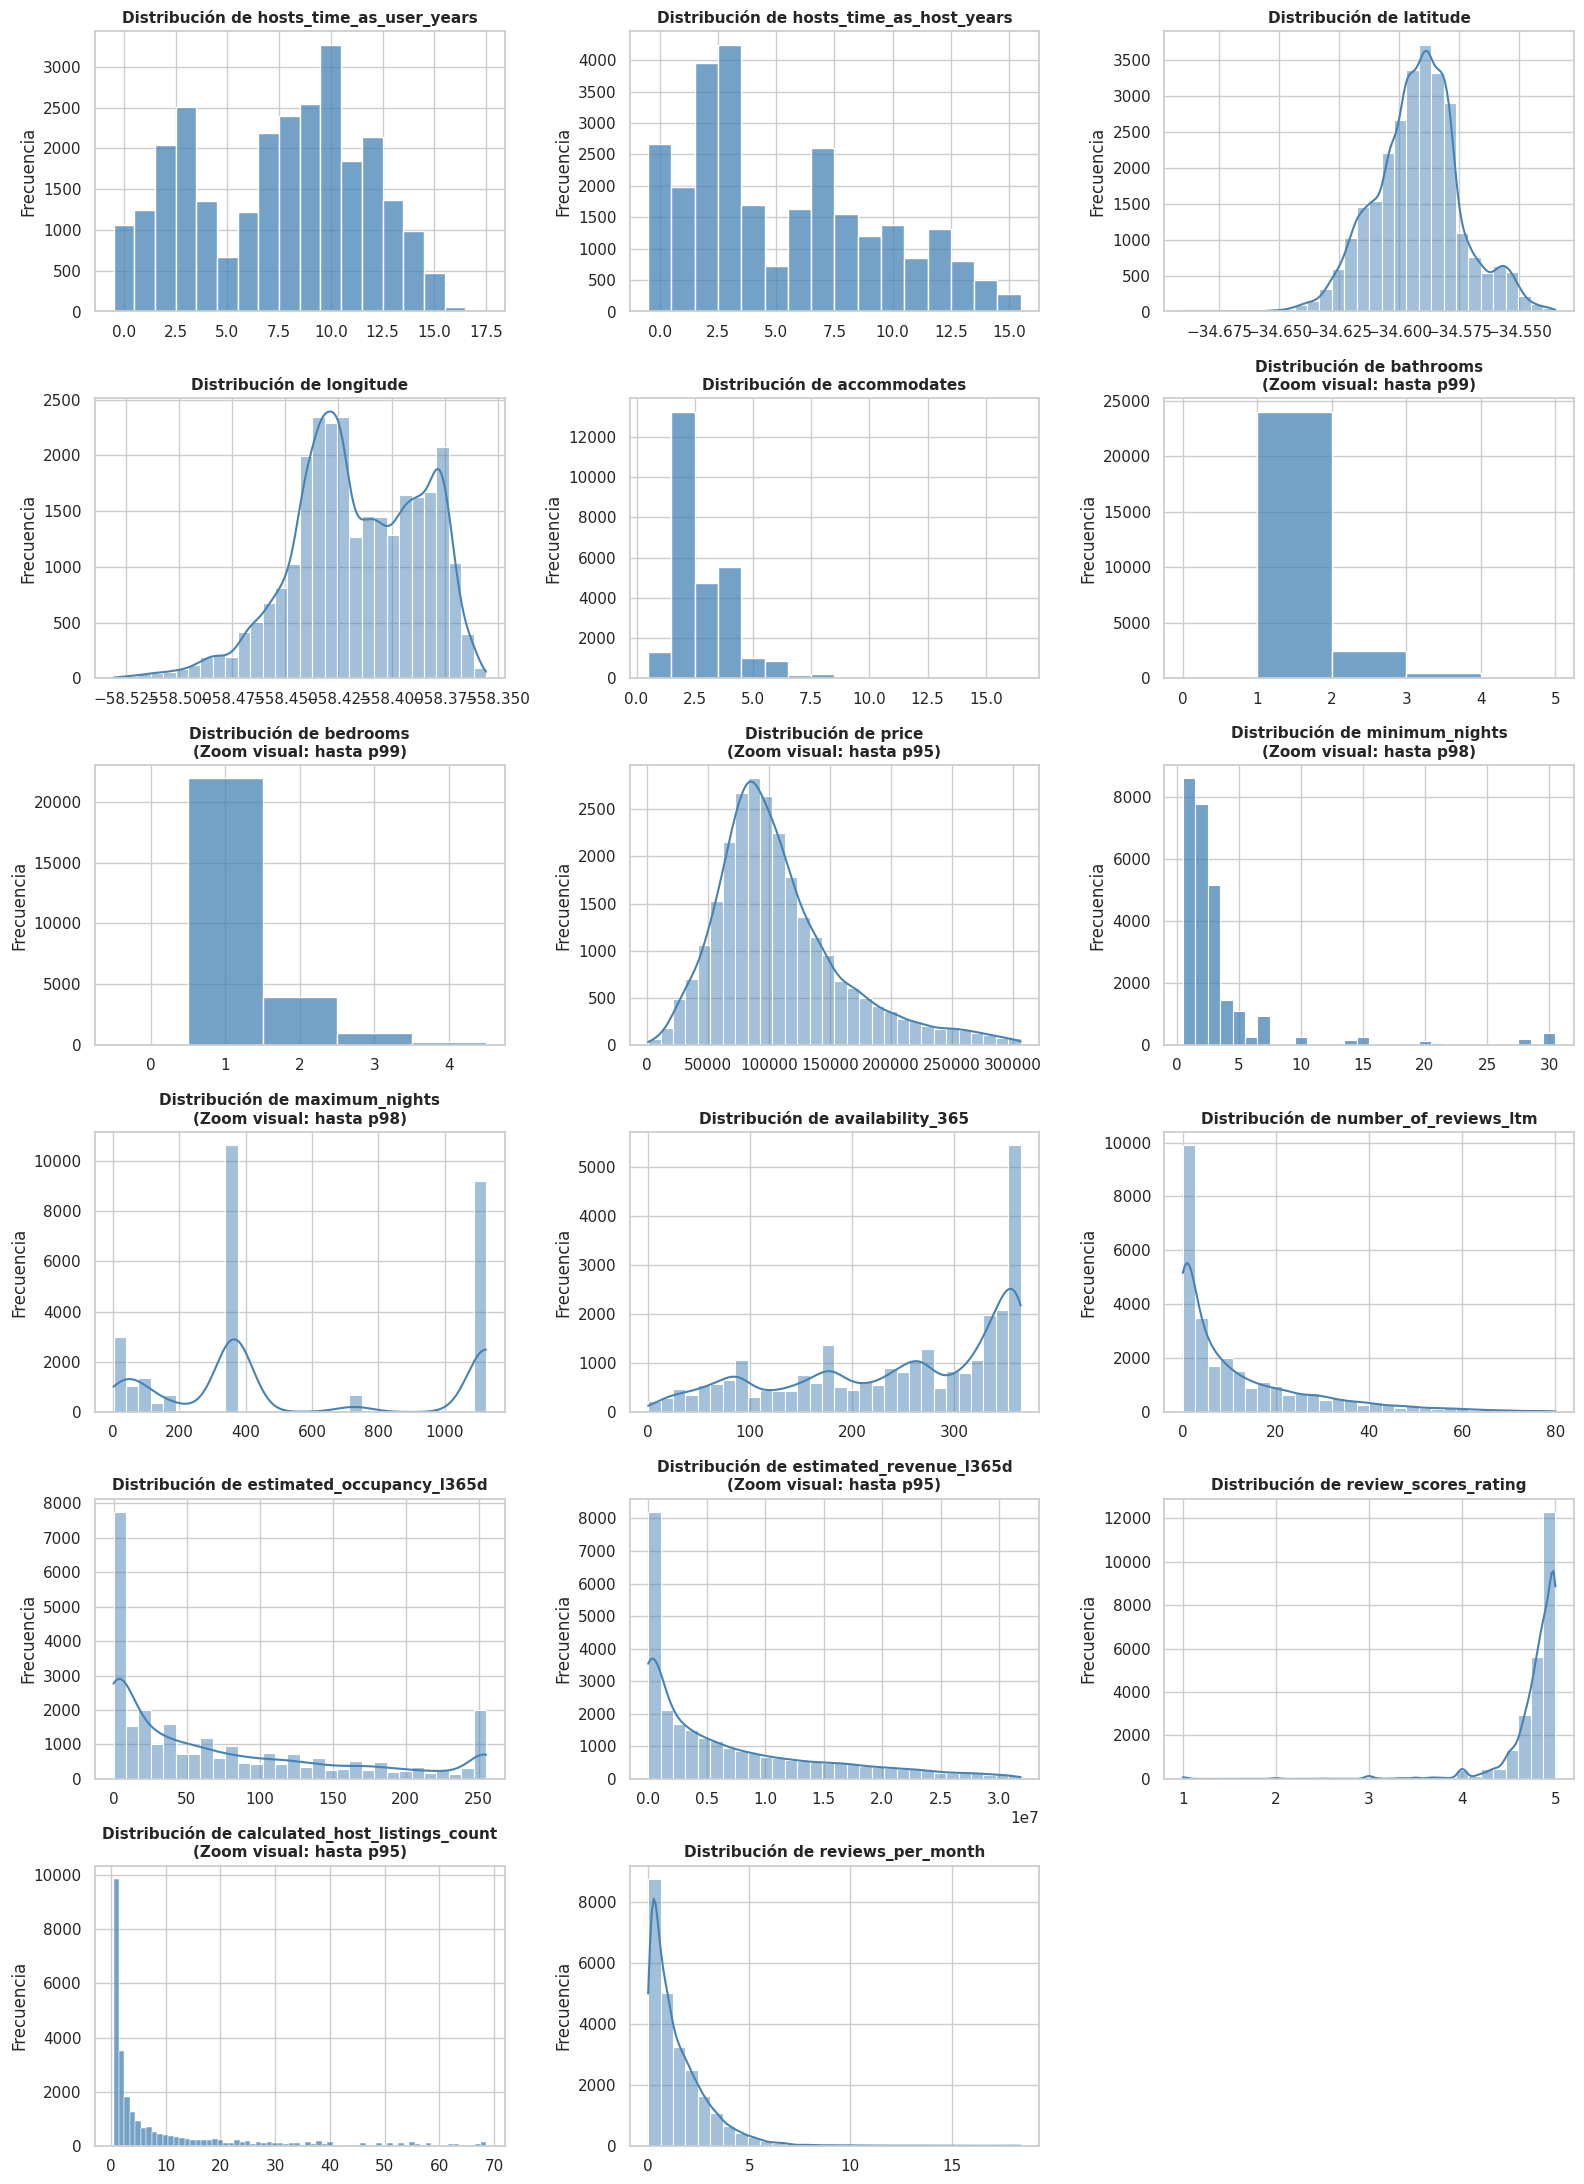

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

variables_numericas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'latitude', 'longitude', 
    'accommodates', 'bathrooms', 'bedrooms', 'price', 'minimum_nights', 
    'maximum_nights', 'availability_365', 'number_of_reviews_ltm', 
    'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]

# Sacamos 'maximum_nights' de esta lista para que no colapse el renderizado
variables_discretas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'accommodates', 
    'bathrooms', 'bedrooms', 'minimum_nights', 'calculated_host_listings_count'
]

# Variables que requieren recorte visual por su extrema asimetría
variables_con_zoom = {
    'price': 0.95,
    'estimated_revenue_l365d': 0.95,
    'minimum_nights': 0.98,
    'maximum_nights': 0.98,
    'bathrooms': 0.99,
    'bedrooms': 0.99,
    'calculated_host_listings_count': 0.95
}

# Se agrega la 'r' (raw string) para evitar el SyntaxWarning en Python 3.12+
if df_copia['price'].dtype == 'object':
    df_copia['price'] = df_copia['price'].replace(r'[\$,]', '', regex=True).astype(float)

fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(16, 22))
axes = axes.flatten()
sns.set_theme(style="whitegrid")

for i, col in enumerate(variables_numericas):
    if col in df_copia.columns:
        datos = df_copia[col].dropna()
        titulo = f'Distribución de {col}'
        
        # Aplicamos el zoom si corresponde
        if col in variables_con_zoom:
            percentil = variables_con_zoom[col]
            datos = datos[datos <= datos.quantile(percentil)]
            titulo += f'\n(Zoom visual: hasta p{int(percentil*100)})'
            
        # Lógica de graficado: Discreta vs Continua
        if col in variables_discretas:
            # Graficado discreto
            sns.histplot(datos, discrete=True, kde=False, ax=axes[i], color='steelblue')
        else:
            # Graficado continuo (ahora maximum_nights usará este formato)
            sns.histplot(datos, bins=30, kde=True, ax=axes[i], color='steelblue')
        
        axes[i].set_title(titulo, fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Frecuencia')

# Eliminamos los ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()